# Temporal decay fit

This plots the per-pixel fit of $\gamma(t) = \gamma_\infty + (1 - \gamma_\infty)e^{-t/\tau}$ made by `scripts/fit_decay.py` (submitted with `slurm/fit_decay.sbatch`).

In [1]:
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.taus import decorrelation_temporal_model

Open the output Zarr of the fit. The selection that was used (variable, dates, tracks) is stored in its attributes.

In [40]:
data_dir = "../data/"
res = '80m'
track = 19

fit = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/decay_dry_{res}.zarr', consolidated=False).load()
# fit = xr.open_zarr(f'../outputs/decay_test.zarr/').load()

{k: fit.attrs[k] for k in ['var', 'gamma_inf', 'start_date', 'end_date', 'max_days', 'stores', 'n_pairs_fit']}

{'var': 'coherence',
 'gamma_inf': 'fit',
 'start_date': '2025-12-01',
 'end_date': '2026-02-28',
 'max_days': 'None',
 'stores': ['data/nisar/zarrs/all_pairs/track019/gunw_80m.zarr'],
 'n_pairs_fit': 28}

Plot $\tau$ and $\gamma_\infty$. Pixels that were not fit (too few valid pairs, or no convergence) are blank.

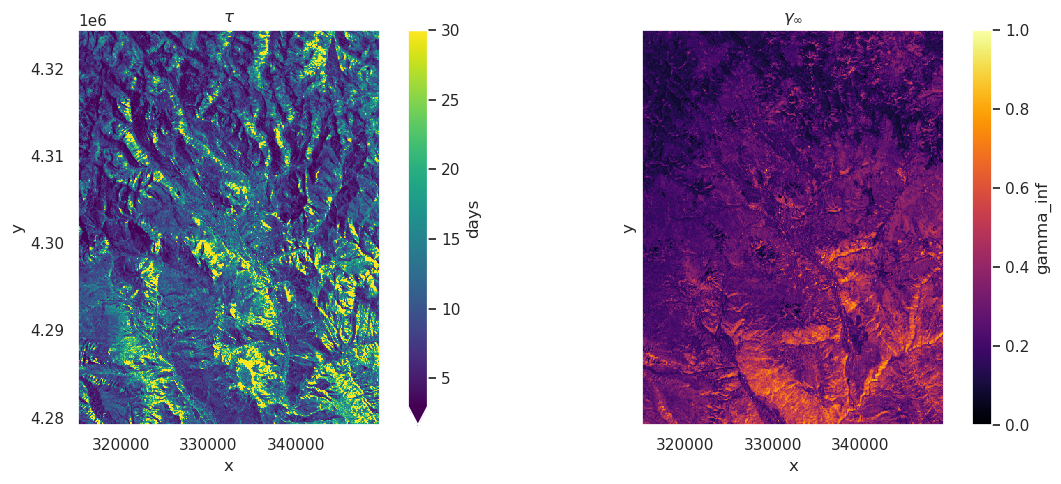

In [41]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
fit['tau'].plot(ax=axs[0], cmap='viridis', robust=True, cbar_kwargs={'label': 'days'})
axs[0].set_title(r'$\tau$')
fit['gamma_inf'].plot(ax=axs[1], cmap='inferno', vmin=0, vmax=1)
axs[1].set_title(r'$\gamma_\infty$')
for ax in axs:
    ax.set_aspect('equal')
plt.tight_layout()

Plot R$^2$ of the fit, to see where the exponential model describes the coherence series poorly. If the fit was run with `--metrics`, the 1-sigma parameter errors are plotted too.

In [ ]:
# R^2 always; the errors only if the fit was run with --metrics (gamma_inf_err is empty if gamma_inf was fixed)
panels = [('r2', r'fit $R^2$', dict(cmap='viridis', vmin=0, vmax=1, cbar_kwargs={'label': r'$R^2$'}))]
if 'tau_err' in fit:
    panels.append(('tau_err', r'$\tau$ error', dict(cmap='magma', robust=True, cbar_kwargs={'label': 'days'})))
if 'gamma_inf_err' in fit:
    panels.append(('gamma_inf_err', r'$\gamma_\infty$ error', dict(cmap='magma', robust=True)))
fig, axs = plt.subplots(1, len(panels), figsize=(6 * len(panels), 5), sharey=True, squeeze=False)
for ax, (name, title, kw) in zip(axs[0], panels):
    fit[name].plot(ax=ax, **kw)
    ax.set_title(title)
    ax.set_aspect('equal')
plt.tight_layout()

Plot how many pairs went into each pixel and where the fit succeeded. Zero pairs inside a tile that ran means no data there; zero everywhere in a tile means the tile never ran.

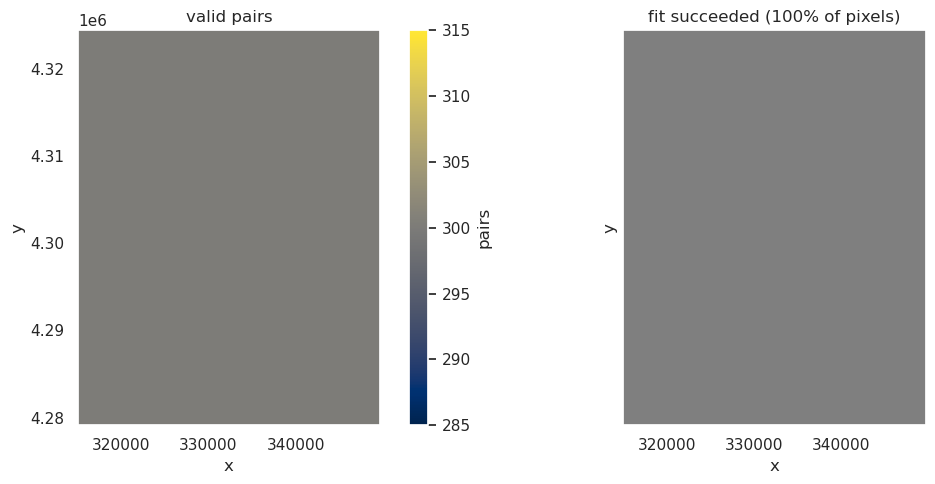

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
fit['n_pairs'].plot(ax=axs[0], cmap='cividis', cbar_kwargs={'label': 'pairs'})
axs[0].set_title('valid pairs')
fit['success'].astype(int).plot(ax=axs[1], cmap='gray_r', add_colorbar=False)
axs[1].set_title(f"fit succeeded ({float(fit['success'].mean()) * 100:.0f}% of pixels)")
for ax in axs:
    ax.set_aspect('equal')
plt.tight_layout()

Histograms of the fitted parameters over all successful pixels.

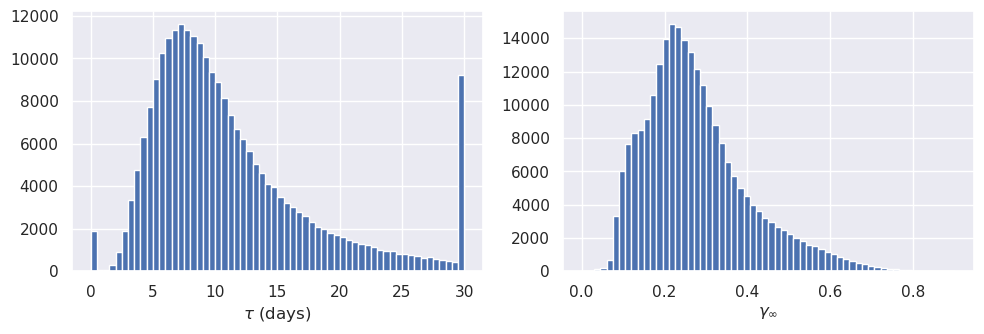

In [43]:
ok = fit['success'].values
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].hist(fit['tau'].values[ok], bins=60)
axs[0].set_xlabel(r'$\tau$ (days)')
axs[1].hist(fit['gamma_inf'].values[ok], bins=60)
axs[1].set_xlabel(r'$\gamma_\infty$')
plt.tight_layout()

Check the fit at one pixel against its coherence time series. Pick a pixel by its x and y coordinates.

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)


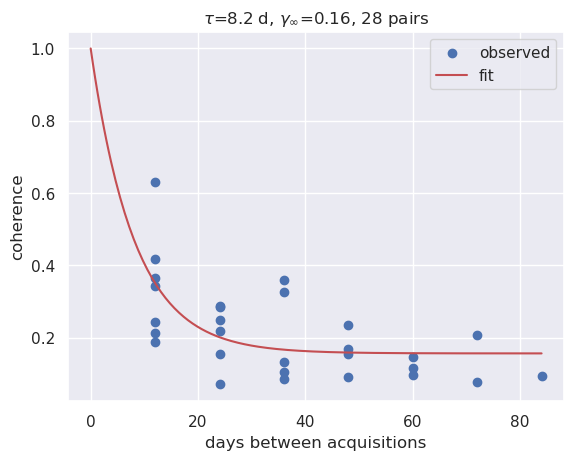

In [44]:
def none_or(value, cast):
    # the fit stores its dates and limits as strings, with 'None' meaning no limit
    return None if value == 'None' else cast(value)

start_date = none_or(fit.attrs['start_date'], np.datetime64)
end_date = none_or(fit.attrs['end_date'], np.datetime64)
max_days = none_or(fit.attrs['max_days'], float)

series, days = [], []
for store in fit.attrs['stores']:
    ds = xr.open_zarr('../' + store)
    start, end = ds['start'].values, ds['end'].values
    keep = np.ones(start.shape, dtype=bool)
    if start_date is not None:
        keep &= start >= start_date
    if end_date is not None:
        keep &= end < end_date + np.timedelta64(1, 'D')  # the whole end day counts
    if max_days is not None:
        keep &= (end - start) / np.timedelta64(1, 'D') <= max_days
    series.append(ds[fit.attrs['var']].isel(pair=np.flatnonzero(keep)))
    days.append(((end - start) / np.timedelta64(1, 'D'))[keep])
cube = xr.concat(series, dim='pair')
days = np.concatenate(days)

# use the successfully fit pixel with the most valid pairs
iy, ix = np.unravel_index(fit['n_pairs'].where(fit['success']).fillna(0).argmax().item(), fit['n_pairs'].shape)
p = fit.isel(y=iy, x=ix)
obs = cube.isel(y=iy, x=ix).values

t = np.linspace(0, days.max(), 200)
plt.scatter(days, obs, label='observed')
plt.plot(t, decorrelation_temporal_model(t, float(p['gamma_inf']), float(p['tau'])), 'r', label='fit')
plt.xlabel('days between acquisitions')
plt.ylabel(fit.attrs['var'])
plt.title(rf"$\tau$={float(p['tau']):.1f} d, $\gamma_\infty$={float(p['gamma_inf']):.2f}, {int(p['n_pairs'])} pairs")
plt.legend();